# Simple Sentiment Analysis Using Deep Learning


## 1. Import required libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the IMDB dataset


In [2]:
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

print("Training reviews:", len(x_train))
print("Testing reviews:", len(x_test))
print("Example label:", y_train[0], "(1 = positive, 0 = negative)")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
Example label: 1 (1 = positive, 0 = negative)


## 3. Prepare the review sequences


In [3]:
x_train_pad = pad_sequences(
    x_train, maxlen=max_length, padding="post", truncating="post"
)
x_test_pad = pad_sequences(
    x_test, maxlen=max_length, padding="post", truncating="post"
)

print("Padded training shape:", x_train_pad.shape)
print("Padded testing shape:", x_test_pad.shape)

Padded training shape: (25000, 200)
Padded testing shape: (25000, 200)


## 4. Build the sentiment analysis model


In [10]:
model = models.Sequential([
    layers.Input(shape=(max_length,)),
    layers.Embedding(vocab_size, 64),
    layers.Bidirectional(layers.LSTM(32)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,945 (2.54 MB)

 Trainable params: 666,945 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the model

In [11]:
history = model.fit(
    x_train_pad,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 301ms/step - accuracy: 0.6852 - loss: 0.5733 - val_accuracy: 0.8254 - val_loss: 0.4072
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 282ms/step - accuracy: 0.8702 - loss: 0.3381 - val_accuracy: 0.8640 - val_loss: 0.3261
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 82s 283ms/step - accuracy: 0.9125 - loss: 0.2448 - val_accuracy: 0.8702 - val_loss: 0.3405
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 45s 282ms/step - accuracy: 0.9383 - loss: 0.1858 - val_accuracy: 0.8336 - val_loss: 0.4025
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 44s 279ms/step - accuracy: 0.9542 - loss: 0.1375 - val_accuracy: 0.8592 - val_loss: 0.4764


## 6. Evaluate the model using test reviews

In [12]:
test_loss, test_accuracy = model.evaluate(x_test_pad, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 83.63%
Test loss: 0.5678


## 7. Plot training and validation accuracy

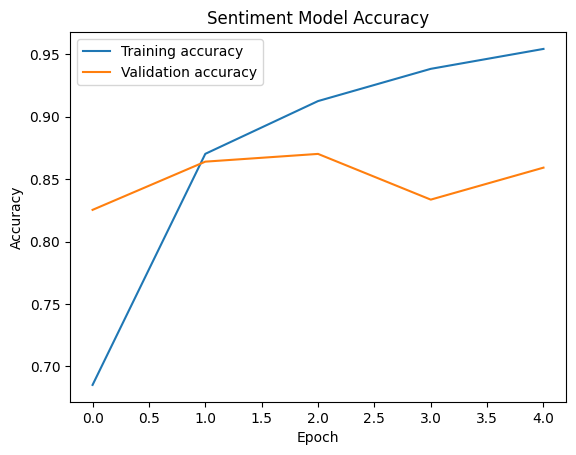

In [13]:
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Sentiment Model Accuracy")
plt.legend()
plt.show()

## 8. Predict sentiment for a new review


In [14]:
word_index = imdb.get_word_index()

def encode_review(text):
    words = text.lower().split()
    sequence = [1]  # IMDB start token
    for word in words:
        word = word.strip(".,!?;:\"'()[]{}")
        index = word_index.get(word)
        # IMDB reserves 0 for padding, 1 for start, and 2 for unknown words.
        sequence.append(index + 3 if index is not None and index + 3 < vocab_size else 2)

    return pad_sequences(
        [sequence], maxlen=max_length, padding="post", truncating="post"
    )

def predict_sentiment(review):
    prepared_review = encode_review(review)
    probability = float(model.predict(prepared_review, verbose=0)[0][0])
    sentiment = "Positive" if probability >= 0.5 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability:.2f}")

predict_sentiment("This movie was wonderful and the story was amazing")

Review: This movie was wonderful and the story was amazing
Predicted sentiment: Positive
Positive probability: 0.99


## 9. Try another review

In [15]:
predict_sentiment("The movie was boring and I did not enjoy it")

predict_sentiment("This movie was wonderful and amazing")

Review: The movie was boring and I did not enjoy it
Predicted sentiment: Negative
Positive probability: 0.11
Review: This movie was wonderful and amazing
Predicted sentiment: Positive
Positive probability: 0.99
